<center><h1>Zambrano_Claudia_Midterm_1</h1></center>
<br>
<br>

USC ID: 8224948861

First part of this file is used for calculations and graphing. Scroll down for question 8

In [27]:
#Tools
import numpy as np
from scipy.optimize import brentq
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from collections import Counter
import scipy.stats as stats
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.model_selection import train_test_split


Question 1


class 3 -> class 1 at x = 0.083
class 1 -> class 2 at x = 14.295
class 2 -> class 3 at x = 902.967


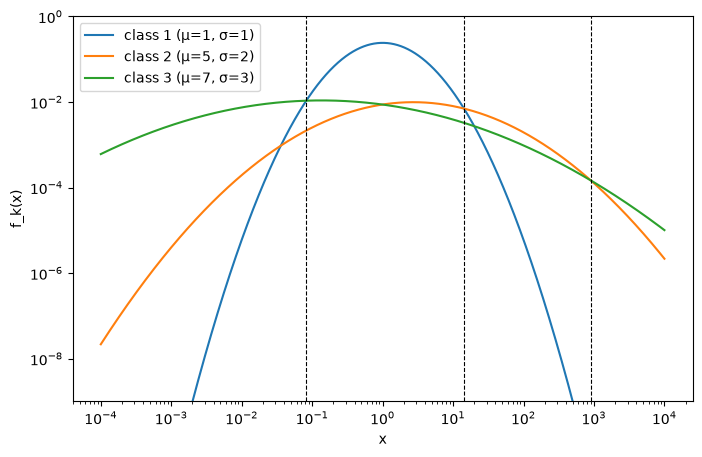

class 3: 0.000 < x < 0.083
class 1: 0.083 < x < 14.295
class 2: 14.295 < x < 902.954
class 3: 902.954 < x < inf

Part (b)
formula  x* = 20.085536923187668
f1(x*)   = 0.0060235065023280816
f2(x*)   = 0.0060235065023280816
numerical x* = 20.085536923187668


In [5]:

def lognormal_pdf(x, m, s):
    return np.exp(-(np.log(x) - m)**2 / (2 * s**2)) / (x * np.sqrt(2 * np.pi) * s)

# ---------- Part (a): K = 3, equal priors ----------
mu    = [1, 5, 7]
sigma = [1, 2, 3]

# Classify on a fine grid in u = ln(x) and find where the winner changes
u = np.linspace(-10, 16, 1_000_001)
x = np.exp(u)
F = np.array([lognormal_pdf(x, m, s) for m, s in zip(mu, sigma)])
winner = F.argmax(axis=0) + 1                    # equal priors, so compare f_k only

idx = np.where(np.diff(winner) != 0)[0]          # indices where the winner changes
for i in idx:
    # refine each boundary by solving f_a(x) = f_b(x) exactly
    a, b = winner[i] - 1, winner[i + 1] - 1
    g = lambda t: lognormal_pdf(np.exp(t), mu[a], sigma[a]) - lognormal_pdf(np.exp(t), mu[b], sigma[b])
    t_star = brentq(g, u[i], u[i + 1])
    print(f"class {a+1} -> class {b+1} at x = {np.exp(t_star):.3f}")

x_plot = np.logspace(-4, 4, 5000)  # Rename to x_plot to avoid overwriting x

fig, ax = plt.subplots(figsize=(8, 5))
for k in range(3):
    ax.plot(x_plot, lognormal_pdf(x_plot, mu[k], sigma[k]),
            label=f"class {k+1} (μ={mu[k]}, σ={sigma[k]})")

# decision boundaries
for b in [0.082, 14.3, 903]:
    ax.axvline(b, color="k", ls="--", lw=0.8)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(1e-9, 1)
ax.set_xlabel("x")
ax.set_ylabel("f_k(x)")
ax.legend()
plt.show()


# Print the resulting regions
edges = [0] + [x[i] for i in idx] + [np.inf]
for lo, hi, k in zip(edges[:-1], edges[1:], [winner[0]] + [winner[i + 1] for i in idx]):
    print(f"class {k}: {lo:.3f} < x < {hi:.3f}")


# ---------- Part (b): K = 2, sigma1 = sigma2, equal priors ----------
mu1, mu2, s = 1.0, 5.0, 2.0                      # any mu1 != mu2 and any common s
x_star = np.sqrt(np.exp(mu1)) * np.sqrt(np.exp(mu2))

print("\nPart (b)")
print("formula  x* =", x_star)
print("f1(x*)   =", lognormal_pdf(x_star, mu1, s))
print("f2(x*)   =", lognormal_pdf(x_star, mu2, s))   # equal to f1(x*), confirming the boundary

# Numerical root-finder as a second check
g = lambda t: lognormal_pdf(np.exp(t), mu1, s) - lognormal_pdf(np.exp(t), mu2, s)
print("numerical x* =", np.exp(brentq(g, mu1, mu2)))

Question 2

In [6]:
X1 = np.array([1, 1, -1, -1])
X2 = np.array([-1, 1, 1, -1])
Y  = np.array([1, 1, 0, 0])

def nll(b):
    b0, b1, b2 = b
    odds = b0 * np.abs(X1)**b1 * np.abs(X2)**b2
    p = odds / (1 + odds)
    return -np.sum(Y*np.log(p) + (1-Y)*np.log(1-p))

res = minimize(nll, x0=[2, 0.5, 0.5], bounds=[(1e-6, None), (None, None), (None, None)])
print(res.x)   # b0 ≈ 1; b1, b2 stay at their starting values

[1.00000452 0.5        0.5       ]


Question 4


In [8]:
y = ['+', '-', '-', '*', '-', '+', '+', '*', '+']
priority = {'*': 0, '+': 1, '-': 2}   # tie-break order: * then +

errors = 0
for i in range(len(y)):
    train = y[:i] + y[i+1:]
    counts = Counter(train)
    # max count; ties broken by priority
    pred = min(counts, key=lambda c: (-counts[c], priority[c]))
    errors += (pred != y[i])
    print(f"leave out {i+1} ({y[i]}): predict {pred}, {'OK' if pred == y[i] else 'ERROR'}")

print(f"Errors: {errors}/{len(y)} = {errors/len(y):.4f}")

leave out 1 (+): predict +, OK
leave out 2 (-): predict +, ERROR
leave out 3 (-): predict +, ERROR
leave out 4 (*): predict +, ERROR
leave out 5 (-): predict +, ERROR
leave out 6 (+): predict +, OK
leave out 7 (+): predict +, OK
leave out 8 (*): predict +, ERROR
leave out 9 (+): predict +, OK
Errors: 5/9 = 0.5556


Question 6

Finding a t-score since standard tables do not have this

In [13]:
#Parameters
df = 24
confidence_level = 0.94

#two-tailed test
alpha = 1 - confidence_level
tail_area = alpha / 2

# Calculate critical t-score
# ppf (percent point function) is the inverse of the CDF
t_critical = stats.t.ppf(1 - tail_area, df)

print(f"Degrees of Freedom (df): {df}")
print(f"Confidence Level: {confidence_level * 100}%")
print(f"Critical t-score: {t_critical:.4f}")

Degrees of Freedom (df): 24
Confidence Level: 94.0%
Critical t-score: 1.9740


Question 7d.

In [14]:
"""KNN (k=3) estimate of weight from height, with distance tables."""

# Training data: (person, height_cm, weight_kg)
train = [
    (1, 171, 80),
    (2, 168, 78),
    (3, 191, 100),
    (4, 182, 80),
    (5, 150, 65),
    (6, 178, 83),
]

test_heights = [150, 155, 165, 190]
k = 3


def regression(h):
    """Regression function from part (b): E[W|H=h] = 0.5 * h^1.001"""
    return 0.5 * h ** 1.001


knn_results = {}

for h_test in test_heights:
    # distance = |training height - test height|
    rows = [(p, h, w, abs(h - h_test)) for p, h, w in train]

    # sort by distance (smallest first)
    rows.sort(key=lambda r: r[3])

    # take the k nearest and average their weights
    neighbors = rows[:k]
    estimate = sum(r[2] for r in neighbors) / k
    knn_results[h_test] = (neighbors, estimate)

    # Print the distance table for this test height
    print(f"\n## Test height {h_test}")
    print(f"{'Person':<8}{'Height':<8}{'Weight':<8}{'Distance':<10}")
    for p, h, w, d in rows:
        mark = "  <-- neighbor" if (p, h, w, d) in neighbors else ""
        print(f"{p:<8}{h:<8}{w:<8}{d:<10}{mark}")

    ids = ", ".join(f"P{r[0]}" for r in neighbors)
    wts = " + ".join(str(r[2]) for r in neighbors)
    print(f"Neighbors: {ids}")
    print(f"Estimate = ({wts}) / {k} = {estimate:.2f} kg")

# Summary table
print("\n## Summary")
print(f"{'Height (cm)':<13}{'3 nearest neighbors':<22}{'KNN estimate (kg)':<20}")
for h_test in test_heights:
    neighbors, est = knn_results[h_test]
    ids = ", ".join(f"P{r[0]}" for r in neighbors)
    print(f"{h_test:<13}{ids:<22}{est:<20.2f}")



## Test height 150
Person  Height  Weight  Distance  
5       150     65      0           <-- neighbor
2       168     78      18          <-- neighbor
1       171     80      21          <-- neighbor
6       178     83      28        
4       182     80      32        
3       191     100     41        
Neighbors: P5, P2, P1
Estimate = (65 + 78 + 80) / 3 = 74.33 kg

## Test height 155
Person  Height  Weight  Distance  
5       150     65      5           <-- neighbor
2       168     78      13          <-- neighbor
1       171     80      16          <-- neighbor
6       178     83      23        
4       182     80      27        
3       191     100     36        
Neighbors: P5, P2, P1
Estimate = (65 + 78 + 80) / 3 = 74.33 kg

## Test height 165
Person  Height  Weight  Distance  
2       168     78      3           <-- neighbor
1       171     80      6           <-- neighbor
6       178     83      13          <-- neighbor
5       150     65      15        
4       182     80     

### **Question 8**


a. Data Exploration and Pre-processing

i. Import Data

In [16]:
#DataFrame
Mf = pd.read_csv('student-mat-fix.csv')
Pf = pd.read_csv('student-POR-fix.csv')

ii. Select features

In [17]:
# Define the list of independent features
features_list = ['age', 'studytime', 'schoolsup', 'goout', 'Dalc', 'Walc', 'health', 'absences']
target = 'G3'

# Separate for Portuguese dataset (Pf) using copy to prevent SettingWithCopyWarning
X_por = Mf[features_list].copy()
y_por = Mf[target].copy()

# Separate for Math dataset (Mf) using copy to prevent SettingWithCopyWarning
X_mat = Pf[features_list].copy()
y_mat = Pf[target].copy()

# Turn schoolsup into binary
X_por['schoolsup'] = X_por['schoolsup'].apply(lambda x: 1 if x == 'yes' else 0)
X_mat['schoolsup'] = X_mat['schoolsup'].apply(lambda x: 1 if x == 'yes' else 0)

# Average of Dalc and Walc
X_por['alc'] = (X_por['Dalc'] + X_por['Walc']) / 2
X_mat['alc'] = (X_mat['Dalc'] + X_mat['Walc']) / 2

# Drop the original 'Dalc' and 'Walc' columns
X_por = X_por.drop(columns=['Dalc', 'Walc'])
X_mat = X_mat.drop(columns=['Dalc', 'Walc'])

# Display sample of the features and target
print("Portuguese Dataset Features (First 5 rows):")
display(X_por.head())
print("\nPortuguese Dataset Target (First 5 rows):")
display(y_por.head())

print("\nMath Dataset Features (First 5 rows):")
display(X_mat.head())
print("\nMath Dataset Target (First 5 rows):")
display(y_mat.head())

Portuguese Dataset Features (First 5 rows):


,age,studytime,schoolsup,goout,health,absences,alc
0,18,2,1,4,3,6,1.0
1,17,2,0,3,3,4,1.0
2,15,2,1,2,3,10,2.5
3,15,3,0,2,5,2,1.0
4,16,2,0,2,5,4,1.5



Portuguese Dataset Target (First 5 rows):


0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64


Math Dataset Features (First 5 rows):


,age,studytime,schoolsup,goout,health,absences,alc
0,18,2,1,4,3,4,1.0
1,17,2,0,3,3,2,1.0
2,15,2,1,2,3,6,2.5
3,15,3,0,2,5,0,1.0
4,16,2,0,2,5,0,1.5



Math Dataset Target (First 5 rows):


0    11
1    11
2    12
3    14
4    13
Name: G3, dtype: int64

iii. Find Outliers

In [18]:
def count_outliers_iqr(df):
    outlier_counts = {}
    for column in df.columns:
        # Skip binary schoolsup as IQR outlier detection is for continuous/ordinal scale features
        if column == 'schoolsup':
            outlier_counts[column] = 0
            continue

        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Count outliers
        outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
        outlier_counts[column] = len(outliers)

    return pd.Series(outlier_counts)

print("Outlier Counts in Portuguese Dataset:")
print(count_outliers_iqr(X_por))

print("\nOutlier Counts in Math Dataset:")
print(count_outliers_iqr(X_mat))

Outlier Counts in Portuguese Dataset:
age           1
studytime    27
schoolsup     0
goout         0
health        0
absences     15
alc           9
dtype: int64

Outlier Counts in Math Dataset:
age           1
studytime    35
schoolsup     0
goout         0
health        0
absences     21
alc          15
dtype: int64


iv. Standardize

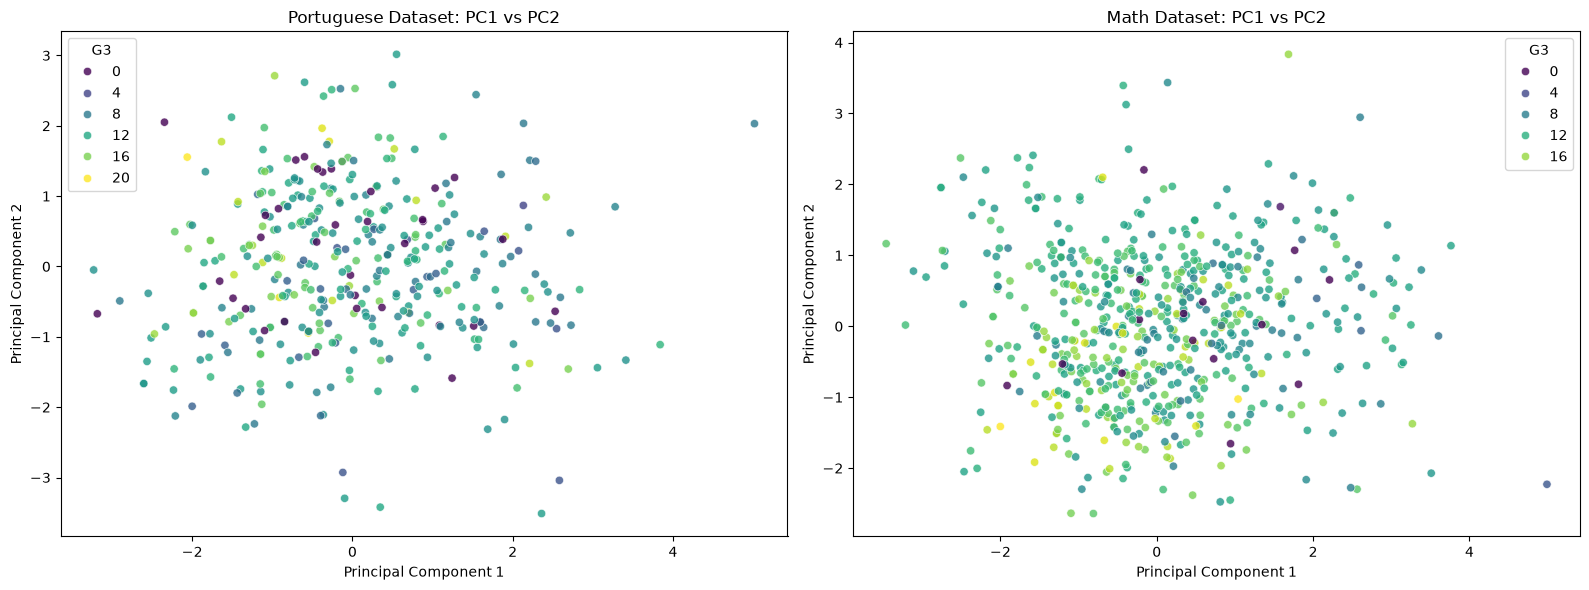

Portuguese Dataset Loadings:


,PC1,PC2
age,0.382,0.589
studytime,-0.330,0.386
schoolsup,-0.248,-0.464
goout,0.494,-0.140
health,0.081,-0.401
absences,0.280,0.183
alc,0.596,-0.274



Math Dataset Loadings:


,PC1,PC2
age,0.338,-0.509
studytime,-0.341,-0.275
schoolsup,-0.269,0.467
goout,0.478,0.147
health,0.074,0.550
absences,0.374,-0.196
alc,0.569,0.292


In [25]:
# Standardization
scaler_por = StandardScaler()
scaler_mat = StandardScaler()

X_por_scaled = scaler_por.fit_transform(X_por)
X_mat_scaled = scaler_mat.fit_transform(X_mat)

# PCA Fitting
pca_por = PCA(n_components=2)
pca_mat = PCA(n_components=2)

PC_por = pca_por.fit_transform(X_por_scaled)
PC_mat = pca_mat.fit_transform(X_mat_scaled)

# Convert to DataFrames for visualization
df_pc_por = pd.DataFrame(data=PC_por, columns=['PC1', 'PC2'])
df_pc_por['G3'] = y_por.values

df_pc_mat = pd.DataFrame(data=PC_mat, columns=['PC1', 'PC2'])
df_pc_mat['G3'] = y_mat.values

# Plot PC1 vs PC2 colored by G3
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    ax=axes[0],
    data=df_pc_por,
    x='PC1',
    y='PC2',
    hue='G3',
    palette='viridis',
    alpha=0.8
)
axes[0].set_title('Portuguese Dataset: PC1 vs PC2')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

sns.scatterplot(
    ax=axes[1],
    data=df_pc_mat,
    x='PC1',
    y='PC2',
    hue='G3',
    palette='viridis',
    alpha=0.8
)
axes[1].set_title('Math Dataset: PC1 vs PC2')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')

plt.tight_layout()
plt.show()

# Component Loadings
loadings_por = pd.DataFrame(
    pca_por.components_.T,
    columns=['PC1', 'PC2'],
    index=X_por.columns
)

loadings_mat = pd.DataFrame(
    pca_mat.components_.T,
    columns=['PC1', 'PC2'],
    index=X_mat.columns
)

print("Portuguese Dataset Loadings:")
display(loadings_por.round(3))

print("\nMath Dataset Loadings:")
display(loadings_mat.round(3))

For Portuguese Dataset


*   PC1 is driven by alchol consumption and going outcontributing the most positively. While study time corresponds negatively
*   PC 2 is driven by age and school  supporting positively, while school support and health contribute the most negatively

For Math Data set


*   PC1 is also driven by alcohol consumption and going out positively while study time is strongest negative contributor
*   PC 2 is driven by health and school support with the highest positivity, while age cotributes the strongest negative loading

**B. Linear Regression**

i. Split Data

In [28]:
# Split Portuguese dataset (using X_por_scaled and y_por)
X_train_por, X_test_por, y_train_por, y_test_por = train_test_split(
    X_por_scaled, y_por, test_size=0.20, random_state=552
)

# Split Math dataset (using X_mat_scaled and y_mat)
X_train_mat, X_test_mat, y_train_mat, y_test_mat = train_test_split(
    X_mat_scaled, y_mat, test_size=0.20, random_state=552
)

# Print shapes to verify the split
print("Portuguese Train set:", X_train_por.shape, y_train_por.shape)
print("Portuguese Test set:", X_test_por.shape, y_test_por.shape)
print("\nMath Train set:", X_train_mat.shape, y_train_mat.shape)
print("Math Test set:", X_test_mat.shape, y_test_mat.shape)

Portuguese Train set: (316, 7) (316,)
Portuguese Test set: (79, 7) (79,)

Math Train set: (519, 7) (519,)
Math Test set: (130, 7) (130,)


ii. Build Models

In [35]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# --- Portuguese Dataset Models ---
# A. Linear Regression
lr_por = LinearRegression()
lr_por.fit(X_train_por, y_train_por)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[-0.78, 0.44,-0.68,...,-0.24, 0.19, 0.04]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,10.63
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](7,)","[22.78,19.95,18.74,...,16.74,14.82,12.93]"


In [36]:
# B. Ridge Regularization
ridge_por = Ridge(alpha=0.1)
ridge_por.fit(X_train_por, y_train_por)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [37]:
# C. Lasso Regularization
lasso_por = Lasso(alpha=0.1)
lasso_por.fit(X_train_por, y_train_por)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [38]:
# --- Math Dataset Models ---
# A. Linear Regression
lr_mat = LinearRegression()
lr_mat.fit(X_train_mat, y_train_mat)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[-0.29, 0.66,-0.33,...,-0.25,-0.11,-0.57]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,11.94
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](7,)","[29.35,24.01,22.84,...,21.02,20.27,17.61]"


In [32]:
# B. Ridge Regularization
ridge_mat = Ridge(alpha=0.1)
ridge_mat.fit(X_train_mat, y_train_mat)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [31]:
# C. Lasso Regularization
lasso_mat = Lasso(alpha=0.1)
lasso_mat.fit(X_train_mat, y_train_mat)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


iii. Test Models

In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def compute_additional_metrics(models, X_train, y_train, X_test, y_test, dataset_name):
    results = []
    for name, model in models.items():
        # Train predictions
        y_pred_train = model.predict(X_train)
        mae_train = mean_absolute_error(y_train, y_pred_train)
        rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
        r2_train = r2_score(y_train, y_pred_train)

        # Test predictions
        y_pred_test = model.predict(X_test)
        mae_test = mean_absolute_error(y_test, y_pred_test)
        rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
        r2_test = r2_score(y_test, y_pred_test)

        results.append({
            'Dataset': dataset_name,
            'Model': name,
            'Train MAE': mae_train,
            'Test MAE': mae_test,
            'Train RMSE': rmse_train,
            'Test RMSE': rmse_test,
            'Train R2': r2_train,
            'Test R2': r2_test
        })
    return pd.DataFrame(results)

# Define the model dictionaries linking to the trained models
por_models = {
    'Linear Regression': lr_por,
    'Ridge Regularization': ridge_por,
    'Lasso Regularization': lasso_por
}

mat_models = {
    'Linear Regression': lr_mat,
    'Ridge Regularization': ridge_mat,
    'Lasso Regularization': lasso_mat
}

# Compute metrics
por_metrics = compute_additional_metrics(por_models, X_train_por, y_train_por, X_test_por, y_test_por, 'Portuguese')
mat_metrics = compute_additional_metrics(mat_models, X_train_mat, y_train_mat, X_test_mat, y_test_mat, 'Math')

all_metrics = pd.concat([por_metrics, mat_metrics], ignore_index=True)
display(all_metrics.round(4))

# Determine best models based on Test set performance (since generalizability is key)
for dataset in ['Portuguese', 'Math']:
    df_subset = all_metrics[all_metrics['Dataset'] == dataset]
    print(f"\n=== Best Models for {dataset} Dataset (Based on Test Set Performance) ===")

    # Best MAE (lower is better)
    best_mae = df_subset.loc[df_subset['Test MAE'].idxmin()]
    print(f"Best MAE: {best_mae['Model']} ({best_mae['Test MAE']:.4f})")

    # Best RMSE (lower is better)
    best_rmse = df_subset.loc[df_subset['Test RMSE'].idxmin()]
    print(f"Best RMSE: {best_rmse['Model']} ({best_rmse['Test RMSE']:.4f})")

    # Best R2 (higher is better)
    best_r2 = df_subset.loc[df_subset['Test R2'].idxmax()]
    print(f"Best R2: {best_r2['Model']} ({best_r2['Test R2']:.4f})")

,Dataset,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Portuguese,Linear Regression,3.1930,3.4180,4.3181,4.7558,0.0748,0.0282
1,Portuguese,Ridge Regularization,3.1930,3.4181,4.3181,4.7559,0.0748,0.0282
2,Portuguese,Lasso Regularization,3.1857,3.4471,4.3261,4.7938,0.0714,0.0126
3,Math,Linear Regression,2.2081,2.3457,3.0337,3.0661,0.1147,0.1041
4,Math,Ridge Regularization,2.2080,2.3456,3.0337,3.0661,0.1147,0.1041
5,Math,Lasso Regularization,2.2217,2.3432,3.0428,3.0746,0.1094,0.0991



=== Best Models for Portuguese Dataset (Based on Test Set Performance) ===
Best MAE: Linear Regression (3.4180)
Best RMSE: Linear Regression (4.7558)
Best R2: Linear Regression (0.0282)

=== Best Models for Math Dataset (Based on Test Set Performance) ===
Best MAE: Lasso Regularization (2.3432)
Best RMSE: Ridge Regularization (3.0661)
Best R2: Ridge Regularization (0.1041)


iv. Interperting R-squared

The absolute value of R² determined the "best" model. With the absolute being closest to 1. Looking at the Test R² for both Portugues and Math datasets, they all seem to be far from 1, which may be a sign of no overfitting.

v. Coefficient

In [40]:
# Get the feature names used for training
feature_names = X_por.columns.tolist()

# Create a DataFrame to hold all coefficients
coeff_df = pd.DataFrame(index=feature_names)

# Extract coefficients for Portuguese dataset models
coeff_df['Por_Linear'] = lr_por.coef_
coeff_df['Por_Ridge'] = ridge_por.coef_
coeff_df['Por_Lasso'] = lasso_por.coef_

# Extract coefficients for Math dataset models
coeff_df['Mat_Linear'] = lr_mat.coef_
coeff_df['Mat_Ridge'] = ridge_mat.coef_
coeff_df['Mat_Lasso'] = lasso_mat.coef_

# Transpose for easier reading (Models as rows, Features as columns)
coeff_df = coeff_df.T
coeff_df.index.name = 'Model'

print("Coefficients of Independent Variables Across All Models:")
display(coeff_df.round(4))

Coefficients of Independent Variables Across All Models:


,age,studytime,schoolsup,goout,health,absences,alc
Model,,,,,,,
Por_Linear,-0.7811,0.4448,-0.6825,-0.5825,-0.2433,0.1928,0.0371
Por_Ridge,-0.7807,0.4447,-0.6822,-0.5823,-0.2432,0.1927,0.0369
Por_Lasso,-0.6304,0.3491,-0.5475,-0.4856,-0.1416,0.0720,-0.0000
Mat_Linear,-0.2859,0.6602,-0.3290,0.0441,-0.2509,-0.1061,-0.5726
Mat_Ridge,-0.2858,0.6601,-0.3289,0.0441,-0.2509,-0.1061,-0.5725
Mat_Lasso,-0.1758,0.5796,-0.2105,-0.0000,-0.1568,-0.0294,-0.4999


*vi. Relationship between independent and dependent variables*

We can see from the table that the Lasso model zeroes out alcohol consumption in the Portuguese data set and zeros out going out in the math dataset. We can also see that coefficients from both the Linear and Redge ression models are almost identical, indicating that the regularization strength is weak.

*vii. How do the regularization methods differ? What can you conclude about the dataset and features given the results?*

Main difference between Lasso and Ridge is that Lasso shrinks the least important features to zero while Ridge gets them very close but not equal to zero.

In the Portuguese dataset we can see that age plays a big impact, while alcohol consumption plays very little or not at all. When thinking of it holistically, the older you are, the more words you know, the better you speak etc. The second highest coefficient would be going out, which makes sense. Going out implies going out with friends and speaking to one another indicating that they practice their language without really noticing it.

In the math datasets the most impactful would be study time while going out has very little effect. Seeing that math is a subject only practiced in school, it makes sense to be the most impacted.

*viii. If the regularization strength (α) is increased, what would happen to performance
metrics?*

If alpha was increased more of our variables would be closer to zero in our ridge regularization and there could be more zero coefficients in lasso regularization. We would be able to ignore the least impactful variables.

*ix. What are some feature engineering methods you would suggest to improve model performance?*

Some features engineering methods to implements would be turning alcohol consumption into binary instead of an average. Based on the results we can see that it either has a big impact or no impact at all.